# Movie Recommender Systems: SVD, Hybrid Model and LLM Agent (MovieLens 1M)

A movie recommender built on the MovieLens 1M ratings (1,000,209 ratings from 6,040 users). It compares matrix factorization (truncated SVD and ALS), a hybrid model with content features and an LLM agent that writes the justifications. Everything is evaluated on held-out data and against demanding baselines.

**Key results**

- **Rating prediction.** ALS on top of a bias baseline reaches a test RMSE of 0.868, versus 0.910 for the user + movie bias baseline (-4.6%). SVD centered only by user (0.968) ended up 6.4% worse than that baseline. Choosing k by explained variance (k = 559) would have worsened RMSE by 5.4% compared with k = 20.
- **Top-10 ranking.** Popularity is a hard baseline: NDCG@10 of 0.178 versus 0.142 for SVD with cosine similarity (a statistically clear difference). But SVD hits almost as often (hit rate 0.61 for both) and recommends 19 times more of the catalog (31% coverage versus 1.7%).
- **Content and demographic attributes.** Adding genre and decade did not improve plain SVD. Adding gender and age made the ranking worse (validation NDCG from 0.055 to 0.039).
- **Five-favorites profile.** Averaging the similarity to the favorites left 1.8 of 5 unrepresented on average; retrieving per favorite covers all of them, at a cost of 16-18% of NDCG.
- **LLM agent.** It writes the justifications, but it only chooses among the candidates it receives; its facts are verified with code.

**Stack:** Python, NumPy, pandas, SciPy, scikit-learn, matplotlib, Gemini API.

## 1. Data

[MovieLens 1M](https://grouplens.org/datasets/movielens/1m/) (GroupLens): 1,000,209 ratings from 1 to 5 given by 6,040 users to 3,706 movies. The catalog has 3,883 movies, but 177 were never rated. Every user rated at least 20. The data include movie genres and each user's gender, age and occupation.

In [1]:
# Libraries
import os, re, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, diags
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import Markdown, display

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
SEED = 42

In [2]:
# MovieLens 1M (GroupLens). If the ml-1m folder does not exist, it is downloaded.
DATA_DIR = 'ml-1m'
URL = 'https://files.grouplens.org/datasets/movielens/ml-1m.zip'
if not os.path.exists(os.path.join(DATA_DIR, 'ratings.dat')):
    urllib.request.urlretrieve(URL, 'ml-1m.zip')
    with zipfile.ZipFile('ml-1m.zip') as z:
        z.extractall('.')

user_df = pd.read_csv(f'{DATA_DIR}/users.dat', header=None, sep='::', engine='python',
                      names=['user_id', 'gender', 'age', 'occupation', 'zip'])
rating_df = pd.read_csv(f'{DATA_DIR}/ratings.dat', header=None, sep='::', engine='python',
                        names=['user_id', 'movie_id', 'rating', 'timestamp'])
movie_df = pd.read_csv(f'{DATA_DIR}/movies.dat', header=None, sep='::', engine='python', encoding='latin-1',
                       names=['movie_id', 'title', 'genres'])

print('Users:', len(user_df), '| Ratings:', len(rating_df), '| Movies in the catalog:', len(movie_df))
print('Scale:', np.sort(rating_df.rating.unique()))
print(rating_df.rating.value_counts().sort_index().to_string())

Users: 6040 | Ratings: 1000209 | Movies in the catalog: 3883
Scale: [1 2 3 4 5]
rating
1     56174
2    107557
3    261197
4    348971
5    226310


## 2. Utility matrix

The work uses index arrays and a **sparse** matrix (CSR): a dense users-by-movies matrix would store millions of zeros that are missing data ("not seen"), not ratings of 0.

In [3]:
users  = rating_df['user_id'].astype('category')
movies = rating_df['movie_id'].astype('category')
ui, mi = users.cat.codes.values.astype(int), movies.cat.codes.values.astype(int)
r = rating_df['rating'].values.astype(float)
n_u, n_m = len(users.cat.categories), len(movies.cat.categories)

names = movie_df.set_index('movie_id')['title'].reindex(movies.cat.categories).tolist()   # title of each column
assert len(set(names)) == n_m, 'duplicate titles found'
genres = movie_df.set_index('movie_id')['genres'].reindex(movies.cat.categories)
genres.index = names

R_all = csr_matrix((r, (ui, mi)), shape=(n_u, n_m))
dens = len(r) / (n_u * n_m)
print(f'Dimension: {n_u} users x {n_m} movies with at least one rating')
print(f'Cells: {n_u * n_m:,} | Ratings: {len(r):,}')
print(f'Density: {dens:.2%} | Sparsity: {1 - dens:.2%}')
print(f'Ratings per user (mean / min / max): {len(r) / n_u:.1f} / {np.bincount(ui).min()} / {np.bincount(ui).max()}')
print(f'Ratings per movie (median / max): {np.median(np.bincount(mi)):.0f} / {np.bincount(mi).max()}')

Dimension: 6040 users x 3706 movies with at least one rating
Cells: 22,384,240 | Ratings: 1,000,209
Density: 4.47% | Sparsity: 95.53%
Ratings per user (mean / min / max): 165.6 / 20 / 2314
Ratings per movie (median / max): 124 / 3428


Only 4.47% of the 22.4 million cells hold a rating (95.53% sparsity). Each user rated 165.6 movies on average, and the median number of ratings per movie is 124 while the maximum is 3,428: a few movies concentrate a large share of the ratings, which matters later for popularity bias.

## 3. Explained variance vs. number of components

The first, naive criterion: how many components to keep to explain 80, 90 and 95% of the variance of the zero-filled matrix.

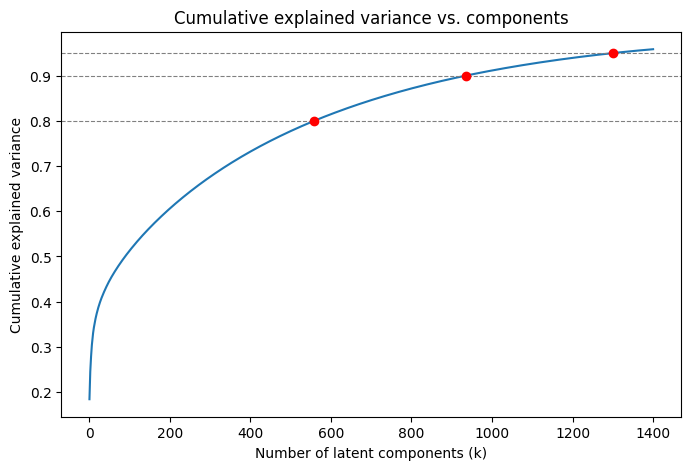

,Range,Initial k,Final k,Additional components,Variance points,Components per point
0,0% -> 80%,0,559,559,80,7.0
1,80% -> 90%,559,935,376,10,37.6
2,90% -> 95%,935,1300,365,5,73.0


80% of the variance: k = 559 (15.1% of the 3706 movies)
90% of the variance: k = 935 (25.2% of the 3706 movies)
95% of the variance: k = 1300 (35.1% of the 3706 movies)


In [4]:
Xt = R_all.T.tocsr()                                   # movies x users (zeros = missing)
N_COMP = min(1400, min(Xt.shape) - 1)
svd_t = TruncatedSVD(n_components=N_COMP, random_state=SEED).fit(Xt)
cum_var = np.cumsum(svd_t.explained_variance_ratio_)

ks_var = {}
for u in (0.80, 0.90, 0.95):
    if cum_var[-1] >= u:
        ks_var[u] = int(np.searchsorted(cum_var, u)) + 1
    else:
        print(f'{u:.0%}: not reached with {N_COMP} components.')

plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(cum_var) + 1), cum_var)
for u, k_u in ks_var.items():
    plt.axhline(u, ls='--', lw=0.8, color='gray')
    plt.scatter(k_u, cum_var[k_u - 1], color='red', zorder=3)
plt.xlabel('Number of latent components (k)'); plt.ylabel('Cumulative explained variance')
plt.title('Cumulative explained variance vs. components'); plt.show()

rows, k_prev, u_prev = [], 0, 0.0
for u, k_u in ks_var.items():
    rows.append({'Range': f'{u_prev:.0%} -> {u:.0%}', 'Initial k': k_prev, 'Final k': k_u,
                  'Additional components': k_u - k_prev, 'Variance points': round((u - u_prev) * 100),
                  'Components per point': round((k_u - k_prev) / ((u - u_prev) * 100), 1)})
    k_prev, u_prev = k_u, u
display(pd.DataFrame(rows))
for u, k_u in ks_var.items():
    print(f'{u:.0%} of the variance: k = {k_u} ({k_u / Xt.shape[0]:.1%} of the {Xt.shape[0]} movies)')

It takes 559, 935 and 1,300 components to explain 80, 90 and 95% of the variance. But that variance measures how well a matrix full of zeros that are not data is reconstructed; it says nothing about how well new ratings are predicted. Section 5 contrasts it with the error on held-out data.

## 4. Evaluation protocol

The ratings are randomly split into **train (70%)**, **validation (10%)** and **test (20%)**. Everything that is fitted (means, biases, SVD, ALS, similarities) uses train only. Validation is used to choose k, hyperparameters and weights; test is used once per block, at the end.

In [5]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(r))
n_te, n_va = int(0.20 * len(r)), int(0.10 * len(r))
te = np.sort(perm[:n_te]); va = np.sort(perm[n_te:n_te + n_va]); tr = np.sort(perm[n_te + n_va:])
print(f'train {len(tr):,} | validation {len(va):,} | test {len(te):,}')

n_tr_user = np.bincount(ui[tr], minlength=n_u)
print('Users with no ratings in train:', int((n_tr_user == 0).sum()),
      '| movies with no ratings in train:', int((np.bincount(mi[tr], minlength=n_m) == 0).sum()))

train 700,148 | validation 100,020 | test 200,041
Users with no ratings in train: 0 | movies with no ratings in train: 45


Every user has ratings in train; 45 movies do not, and the factor models have no information about them.

## 5. Rating prediction (RMSE)

From least to most sophisticated, the comparison includes:

* **Baselines**: global mean, user mean, movie mean and **user + movie bias** (regularized). If a factor model does not beat the last one, it is not adding anything.
* **Truncated SVD** on three versions of the train matrix: zero-filled, user-centered and bias-centered. In the last two, a missing entry means "the expected rating", not 0.
* **ALS** on the bias residual: a factorization that optimizes **only over the observed ratings**, with regularization.

In [6]:
def rmse(pred, idx):
    return float(np.sqrt(np.mean((np.clip(pred, 1, 5) - r[idx]) ** 2)))


def fit_biases(idx, lam_i=10.0, lam_u=15.0, n_iter=5):
    """mu + b_u + b_i with regularization (Koren): biases of users/movies with little data shrink toward 0."""
    mu = r[idx].mean()
    bu, bi = np.zeros(n_u), np.zeros(n_m)
    for _ in range(n_iter):
        bi = np.bincount(mi[idx], weights=r[idx] - mu - bu[ui[idx]], minlength=n_m) / (lam_i + np.bincount(mi[idx], minlength=n_m))
        bu = np.bincount(ui[idx], weights=r[idx] - mu - bi[mi[idx]], minlength=n_u) / (lam_u + np.bincount(ui[idx], minlength=n_u))
    return mu, bu, bi


def means_by(axis_name, idx, mu):
    code_arr = ui if axis_name == 'u' else mi
    n_e = n_u if axis_name == 'u' else n_m
    s, c = np.bincount(code_arr[idx], weights=r[idx], minlength=n_e), np.bincount(code_arr[idx], minlength=n_e)
    return np.where(c > 0, s / np.maximum(c, 1), mu)


mu, bu, bi = fit_biases(tr)
user_mean, item_mean = means_by('u', tr, mu), means_by('i', tr, mu)

def base_pred(name, idx):
    if name == 'global':   return np.full(len(idx), mu)
    if name == 'user':  return user_mean[ui[idx]]
    if name == 'movie': return item_mean[mi[idx]]
    if name == 'biases':   return mu + bu[ui[idx]] + bi[mi[idx]]

baseline_table = pd.DataFrame({
    'Model': ['Global mean', 'User mean', 'Movie mean', 'User + movie bias'],
    'Val RMSE': [rmse(base_pred(n, va), va) for n in ('global', 'user', 'movie', 'biases')],
})
display(baseline_table.round(4))

,Model,Val RMSE
0,Global mean,1.1160
1,User mean,1.0349
2,Movie mean,0.9789
3,User + movie bias,0.9092


On validation, the movie mean (0.979) already beats the user mean (1.035), and adding user and movie biases brings the error down to 0.909. That is the model to beat.

SVD with zeros: listo
SVD centered (user): listo
SVD centered (biases): listo


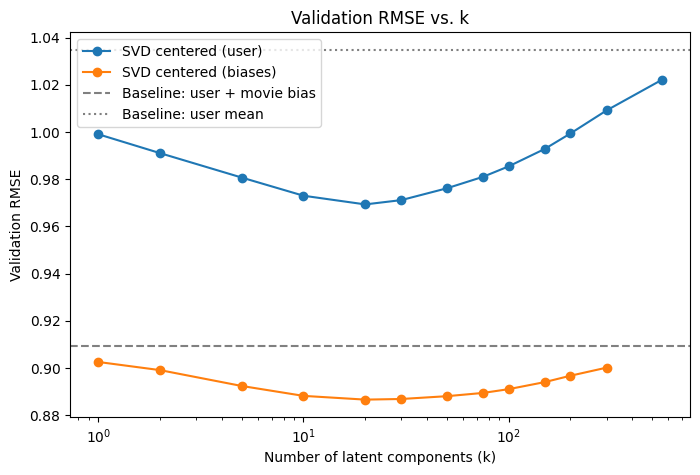

,k in validation,Val RMSE
SVD with zeros,20.0,2.5173
SVD centered (user),20.0,0.9693
SVD centered (biases),20.0,0.8866


With k = 559 (80 % variance criterion) the validation RMSE is 1.0221 versus 0.9693 with k = 20.


In [7]:
def rmse_vs_k(X, base_fn, idx_eval, ks, chunk=20_000):
    """Truncated SVD of X (users x movies, train only). Prediction = base + reconstruction with k components.
    A single fit with the maximum k; reconstructions with smaller k come from cumulative sums."""
    svd = TruncatedSVD(n_components=max(ks), random_state=SEED).fit(X)
    Vt = svd.components_
    Z = X @ Vt.T                                                   # = U·Σ
    u_e, m_e, y, base = ui[idx_eval], mi[idx_eval], r[idx_eval], base_fn(idx_eval)
    sse = np.zeros(len(ks))
    for s in range(0, len(idx_eval), chunk):
        sl = slice(s, s + chunk)
        cum = np.cumsum(Z[u_e[sl]] * Vt[:, m_e[sl]].T, axis=1)
        for q, k in enumerate(ks):
            sse[q] += ((np.clip(base[sl] + cum[:, k - 1], 1, 5) - y[sl]) ** 2).sum()
    return np.sqrt(sse / len(idx_eval))


def train_matrix(vals):
    return csr_matrix((vals, (ui[tr], mi[tr])), shape=(n_u, n_m))

versions = {
    'SVD with zeros':          (train_matrix(r[tr]),                                  lambda idx: np.zeros(len(idx))),
    'SVD centered (user)': (train_matrix(r[tr] - user_mean[ui[tr]]),                  lambda idx: base_pred('user', idx)),
    'SVD centered (biases)':  (train_matrix(r[tr] - mu - bu[ui[tr]] - bi[mi[tr]]),   lambda idx: base_pred('biases', idx)),
}
k_cap = min(n_u, n_m) - 1
ks_short = [k for k in (1, 2, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300) if k < k_cap]
ks_long = ks_short + ([ks_var[0.80]] if 0.80 in ks_var and ks_var[0.80] < k_cap else [])   # includes the "variance-based" k

curves = {}
for name, (X, base_fn) in versions.items():
    ks_m = ks_long if name == 'SVD centered (user)' else ks_short
    curves[name] = (ks_m, rmse_vs_k(X, base_fn, va, ks_m))
    print(f'{name}: listo')

plt.figure(figsize=(8, 5))
for name, (ks_m, e) in curves.items():
    if name != 'SVD with zeros':
        plt.plot(ks_m, e, marker='o', label=name)
plt.axhline(rmse(base_pred('biases', va), va), ls='--', color='gray', label='Baseline: user + movie bias')
plt.axhline(rmse(base_pred('user', va), va), ls=':', color='gray', label='Baseline: user mean')
plt.xscale('log'); plt.xlabel('Number of latent components (k)'); plt.ylabel('Validation RMSE')
plt.title('Validation RMSE vs. k'); plt.legend(); plt.show()

k_best = {n: ks_m[int(np.argmin(e))] for n, (ks_m, e) in curves.items()}
display(pd.DataFrame({n: {'k in validation': k_best[n], 'Val RMSE': round(float(e.min()), 4)} for n, (ks_m, e) in curves.items()}).T)
if 0.80 in ks_var:
    ks_m, e = curves['SVD centered (user)']
    if ks_var[0.80] in ks_m:
        print(f'With k = {ks_var[0.80]} (80 % variance criterion) the validation RMSE is {e[ks_m.index(ks_var[0.80])]:.4f} '
              f'versus {e.min():.4f} with k = {k_best["SVD centered (user)"]}.')

All three SVD versions reach their lowest validation error at k = 20, not at the 559 components of the variance criterion: for the user-centered version the RMSE would be 1.022 instead of 0.969 (5.4% worse), probably because the extra components fit noise. With zero-filled data the error is 2.52, because the model reads missing entries as a rating of 0.

In [8]:
# ALS on the bias residual, optimizing only over observed ratings.
def als(idx, k, lam, n_iter=10, seed=SEED):
    res = r[idx] - mu - bu[ui[idx]] - bi[mi[idx]]
    rg = np.random.default_rng(seed)
    P = np.zeros((n_u, k)); Q = 0.1 * rg.standard_normal((n_m, k))
    Rui = csr_matrix((res, (ui[idx], mi[idx])), shape=(n_u, n_m)); Riu = Rui.T.tocsr()
    I = np.eye(k)

    def step(M, F, fixed):
        for j in range(M.shape[0]):
            a, b = M.indptr[j], M.indptr[j + 1]
            if a == b:
                continue
            Y = fixed[M.indices[a:b]]
            F[j] = np.linalg.solve(Y.T @ Y + lam * (b - a) * I, Y.T @ M.data[a:b])    # regularization weighted by the number of ratings

    for _ in range(n_iter):
        step(Rui, P, Q); step(Riu, Q, P)
    return P, Q


def rmse_als(P, Q, idx):
    return rmse(base_pred('biases', idx) + np.einsum('ij,ij->i', P[ui[idx]], Q[mi[idx]]), idx)


t0 = time.time()
rows, als_models = [], {}
for k_, lam_ in [(20, 0.05), (20, 0.1), (20, 0.2)]:
    P_, Q_ = als(tr, k_, lam_); als_models[(k_, lam_)] = (P_, Q_)
    rows.append({'k': k_, 'lambda': lam_, 'Val RMSE': rmse_als(P_, Q_, va)})
lam_best = min(rows, key=lambda f: f['Val RMSE'])['lambda']
for k_ in (10, 50):
    P_, Q_ = als(tr, k_, lam_best); als_models[(k_, lam_best)] = (P_, Q_)
    rows.append({'k': k_, 'lambda': lam_best, 'Val RMSE': rmse_als(P_, Q_, va)})
als_table = pd.DataFrame(rows).sort_values('Val RMSE')
display(als_table.round(4))
k_als, lam_als = int(als_table.iloc[0]['k']), float(als_table.iloc[0]['lambda'])
P_als, Q_als = als_models[(k_als, lam_als)]
print(f'ALS selected on validation: k = {k_als}, lambda = {lam_als} ({time.time() - t0:.0f} s)')

,k,lambda,Val RMSE
4,50,0.10,0.8674
1,20,0.10,0.8690
3,10,0.10,0.8709
0,20,0.05,0.8786
2,20,0.20,0.9026


ALS selected on validation: k = 50, lambda = 0.1 (54 s)


In [9]:
# Final result on TEST (only once, with what was selected on validation). Models were fit on train only.
res_test = {
    'Global mean':              rmse(base_pred('global', te), te),
    'User mean':         rmse(base_pred('user', te), te),
    'Movie mean':        rmse(base_pred('movie', te), te),
    'User + movie bias':  rmse(base_pred('biases', te), te),
}
for name, (X, base_fn) in versions.items():
    k_ = k_best[name]
    res_test[f'{name} (k={k_})'] = float(rmse_vs_k(X, base_fn, te, [k_])[0])
res_test[f'ALS on biases (k={k_als})'] = rmse_als(P_als, Q_als, te)

rmse_table = pd.DataFrame({'RMSE test': res_test})
ref = res_test['User + movie bias']
rmse_table['vs. user + movie bias'] = (rmse_table['RMSE test'] / ref - 1).map('{:+.1%}'.format)
display(rmse_table.round(4))

,RMSE test,vs. user + movie bias
Global mean,1.1157,+22.6%
User mean,1.0346,+13.7%
Movie mean,0.9804,+7.8%
User + movie bias,0.9099,+0.0%
SVD with zeros (k=20),2.5184,+176.8%
SVD centered (user) (k=20),0.9682,+6.4%
SVD centered (biases) (k=20),0.8873,-2.5%
ALS on biases (k=50),0.8681,-4.6%


**Test result.** The bias baseline (0.910) is the reference. SVD centered only by user (0.968) ends up **6.4% worse**: subtracting the user mean is not enough, the movie effect is missing. Centering by biases lowers the error to 0.887 (-2.5%), and ALS, which ignores missing entries instead of filling them, reaches 0.868 (-4.6%). The improvement over the baseline is modest: most of the signal was already in the biases.

## 6. Movie similarity and hybrid model

**Collaborative recommender**: latent factors for each movie (SVD of the user-centered, transposed matrix) and cosine similarity between movies.

**Hybrid recommender**: normalized blocks (SVD factors, multi-hot genre, decade and, optionally, an audience profile per movie) are concatenated with weights; the resulting cosine is a weighted average of each block's similarity.

The **audience** profile (share of women and of people under 25 among those who rated each movie) uses people's gender and age. The question is whether it adds anything; if it does not improve the ranking, there is no reason to use sensitive attributes.

In [10]:
# ---- movie content (does not depend on the ratings)
year = pd.Series(names).str.extract(r'\((\d{4})\)\s*$')[0].astype(float)
assert year.notna().all()
decade = ((year // 10) * 10).astype(int).values
D = pd.get_dummies(decade).astype(float).values                                   # decade (categorical)
G = genres.reindex(names).fillna('').str.get_dummies(sep='|').values.astype(float)   # genre (multi-hot)
GENRES = list(genres.reindex(names).fillna('').str.get_dummies(sep='|').columns)
print('Decades:', D.shape[1], '| Genres:', G.shape[1])

user_profile = user_df.set_index('user_id').reindex(users.cat.categories)
is_female_u = (user_profile['gender'].values == 'F')
is_young_u = (user_profile['age'].values <= 18)                                      # codes 1 and 18: under 25


def unit(M):
    return M / np.maximum(np.linalg.norm(M, axis=1, keepdims=True), 1e-12)


def audience(idx, m=20):
    """Share of women / young people among those who rated each movie, smoothed toward the global average."""
    n = np.bincount(mi[idx], minlength=n_m)
    out = []
    for flag in (is_female_u, is_young_u):
        f = flag[ui[idx]].astype(float)
        out.append((np.bincount(mi[idx], weights=f, minlength=n_m) + m * f.mean()) / (n + m))
    return np.column_stack(out)


def svd_factors(idx, k, seed=1):
    """Latent factors of the movies: SVD of the user-centered (movies x users) matrix, using only the ratings idx."""
    s, c = np.bincount(ui[idx], weights=r[idx], minlength=n_u), np.bincount(ui[idx], minlength=n_u)
    um = np.where(c > 0, s / np.maximum(c, 1), r[idx].mean())
    X = csr_matrix((r[idx] - um[ui[idx]], (mi[idx], ui[idx])), shape=(n_m, n_u))
    return TruncatedSVD(n_components=k, random_state=seed).fit_transform(X)


def hybrid_sim(F, weights, AUDIENCE=None):
    blocks = {'svd': F, 'genre': G, 'decade': D}
    if AUDIENCE is not None:
        blocks['audience'] = AUDIENCE
    H = np.hstack([np.sqrt(w) * unit(blocks[b]) for b, w in weights.items() if w > 0])
    return cosine_similarity(H).astype(np.float32)

Decades: 10 | Genres: 18


## 7. Ranking evaluation

For each evaluation user, the movies they liked in train (rating >= 4) are the **seeds**; every movie they have not seen is scored and the top 10 is taken. A recommendation is a **hit** if the user rated it >= 4 in the held-out set (validation or test). Unrated movies are treated as non-relevant, so absolute metrics are low; what is informative is the comparison between models.

Metrics: precision@10, recall@10, NDCG@10, hit rate (at least one hit), **coverage** (share of the catalog that ever gets recommended) and the average number of ratings of what is recommended (popularity bias). The **popularity** and **random** baselines are included. The evaluation uses 1,500 users drawn at random from the 5,699 eligible ones (at least 5 liked movies in train and one in validation and in test).

In [11]:
def csr_bin(idx, liked_only=False):
    sel = idx[r[idx] >= 4] if liked_only else idx
    return csr_matrix((np.ones(len(sel), dtype=np.float32), (ui[sel], mi[sel])), shape=(n_u, n_m))

B_tr, B_tr_like = csr_bin(tr), csr_bin(tr, True)
B_va, B_va_like = csr_bin(va), csr_bin(va, True)
B_te_like = csr_bin(te, True)
pop_tr = np.asarray(B_tr.sum(0)).ravel()                      # number of ratings per movie in train

row_count = lambda B: np.asarray(B.sum(1)).ravel()
eligible = np.where((row_count(B_tr_like) >= 5) & (row_count(B_va_like) >= 1) & (row_count(B_te_like) >= 1))[0]
N_EVAL_USERS = 1500
eval_users = np.random.default_rng(SEED).choice(eligible, size=min(N_EVAL_USERS, len(eligible)), replace=False)
print(f'Eligible users: {len(eligible)} | evaluation users: {len(eval_users)}')

K = 10
def topk_metrics(scores, users, split):
    seen = B_tr[users].toarray() > 0
    if split == 'test':
        seen |= B_va[users].toarray() > 0                    # what was rated in validation is already known
    sc = np.where(seen, -np.inf, scores)
    top = np.argpartition(-sc, K, axis=1)[:, :K]
    top = np.take_along_axis(top, np.argsort(-np.take_along_axis(sc, top, 1), axis=1), 1)
    rel = (B_va_like if split == 'val' else B_te_like)[users].toarray() > 0
    hits = np.take_along_axis(rel, top, 1)
    n_rel = rel.sum(1)
    desc = 1 / np.log2(np.arange(2, K + 2))
    ndcg = (hits * desc).sum(1) / np.array([desc[:min(K, n)].sum() for n in n_rel])
    return {'Precision@10': hits.mean(), 'Recall@10': (hits.sum(1) / n_rel).mean(), 'NDCG@10': ndcg.mean(),
            'Hit rate': hits.any(1).mean(), 'Coverage': len(np.unique(top)) / n_m,
            'Avg. ratings of recommended': pop_tr[top].mean()}

# ---- scores of each model for a set of users
def scores_popularity(users):
    return np.tile(pop_tr.astype(float), (len(users), 1))

def scores_random(users):
    return np.random.default_rng(SEED).random((len(users), n_m))

def scores_sim(S, users, agg='mean'):
    Bl = B_tr_like[users]
    if agg == 'mean':                                         # average similarity to all seeds
        n = np.maximum(row_count(Bl), 1)
        return np.asarray(diags(1 / n) @ Bl @ S)
    out = np.empty((len(users), n_m), dtype=np.float32)        # agg == 'max': similarity to the most similar seed
    for q in range(len(users)):
        sem = Bl.indices[Bl.indptr[q]:Bl.indptr[q + 1]]
        out[q] = S[sem].max(0)
    return out

def scores_als(users):
    return P_als[users] @ Q_als.T + bi[None, :]

def row(name, fn, split):
    return {'Model': name, **topk_metrics(fn(eval_users), eval_users, split)}

Eligible users: 5699 | evaluation users: 1500


In [12]:
# ---- selection on VALIDATION: SVD k, hybrid weights
ks_sim = [k for k in (10, 20, 50, 100) if k < k_cap]
F_tr = {k: svd_factors(tr, k) for k in ks_sim}
rows = []
for k in ks_sim:
    S = cosine_similarity(F_tr[k]).astype(np.float32)
    rows.append(row(f'SVD-cosine k={k}', lambda u, S=S: scores_sim(S, u), 'val'))
k_table = pd.DataFrame(rows)
display(k_table.round(4))
k_sim = ks_sim[int(k_table['NDCG@10'].argmax())]
print('k selected for the similarity (NDCG@10 on validation):', k_sim)

GRID = [
    {'svd': .8, 'genre': .2},
    {'svd': .6, 'genre': .4},
    {'svd': .6, 'genre': .3, 'decade': .1},
    {'svd': .4, 'genre': .4, 'decade': .2},
    {'svd': .47, 'genre': .35, 'decade': .18},          # weights of the original version, without audience
]
rows = []
for p in GRID:
    S = hybrid_sim(F_tr[k_sim], p)
    rows.append({'Weights': str(p), **row('hybrid', lambda u, S=S: scores_sim(S, u), 'val')})
weights_table = pd.DataFrame(rows).drop(columns='Model')
display(weights_table.round(4))
weights_h = GRID[int(weights_table['NDCG@10'].argmax())]
print('Weights selected (validation):', weights_h)

,Model,Precision@10,Recall@10,NDCG@10,Hit rate,Coverage,Avg. ratings of recommended
0,SVD-cosine k=10,0.0465,0.0572,0.0591,0.3380,0.3573,552.164612
1,SVD-cosine k=20,0.0561,0.0716,0.0724,0.3973,0.3195,587.237488
2,SVD-cosine k=50,0.0597,0.0732,0.0785,0.4073,0.3001,585.874573
3,SVD-cosine k=100,0.0578,0.0752,0.0797,0.4007,0.3084,558.179993


k selected for the similarity (NDCG@10 on validation): 100


,Weights,Precision@10,Recall@10,NDCG@10,Hit rate,Coverage,Avg. ratings of recommended
0,"{'svd': 0.8, 'genre': 0.2}",0.0547,0.0772,0.0745,0.3713,0.2790,489.732208
1,"{'svd': 0.6, 'genre': 0.4}",0.0475,0.0710,0.0644,0.3427,0.2922,452.937012
2,"{'svd': 0.6, 'genre': 0.3, 'decade': 0.1}",0.0448,0.0714,0.0633,0.3240,0.2874,390.957001
3,"{'svd': 0.4, 'genre': 0.4, 'decade': 0.2}",0.0365,0.0597,0.0520,0.2780,0.3095,372.946991
4,"{'svd': 0.47, 'genre': 0.35, 'decade': 0.18}",0.0382,0.0623,0.0546,0.2833,0.2984,366.683594


Weights selected (validation): {'svd': 0.8, 'genre': 0.2}


In [13]:
# ---- final models of this section, fit on train only
ORIG_WEIGHTS = {'svd': .40, 'genre': .30, 'decade': .15, 'audience': .15}     # weights of the original version (arbitrary)
S_svd  = cosine_similarity(F_tr[k_sim]).astype(np.float32)
S_hyb  = hybrid_sim(F_tr[k_sim], weights_h)
S_hybA = hybrid_sim(F_tr[k_sim], ORIG_WEIGHTS, AUDIENCE=audience(tr))

ranking_models = {
    'Random':                          scores_random,
    'Popularity':                        scores_popularity,
    'ALS (predicted rating)':              scores_als,
    'SVD-cosine (mean of seeds)':     lambda u: scores_sim(S_svd, u),
    'SVD-cosine (most similar seed)':  lambda u: scores_sim(S_svd, u, 'max'),
    'Hybrid without audience (mean)':      lambda u: scores_sim(S_hyb, u),
    'Hybrid without audience (most similar)': lambda u: scores_sim(S_hyb, u, 'max'),
    'Hybrid original with audience (mean)': lambda u: scores_sim(S_hybA, u),
}
val_table  = pd.DataFrame([row(n, f, 'val')  for n, f in ranking_models.items()]).set_index('Model')
print('VALIDATION')
display(val_table.round(4))

VALIDATION


,Precision@10,Recall@10,NDCG@10,Hit rate,Coverage,Avg. ratings of recommended
Model,,,,,,
Random,0.0022,0.0017,0.0021,0.0220,0.9825,175.756500
Popularity,0.0637,0.0701,0.0825,0.4060,0.0127,1871.395142
ALS (predicted rating),0.0287,0.0320,0.0378,0.2313,0.1352,685.246216
SVD-cosine (mean of seeds),0.0578,0.0752,0.0797,0.4007,0.3084,558.179993
SVD-cosine (most similar seed),0.0369,0.0472,0.0530,0.2800,0.3349,406.529205
Hybrid without audience (mean),0.0547,0.0772,0.0745,0.3713,0.2790,489.732208
Hybrid without audience (most similar),0.0437,0.0534,0.0635,0.3233,0.3413,434.284210
Hybrid original with audience (mean),0.0275,0.0484,0.0388,0.2053,0.2647,250.939804


**Selection on validation.** The similarity with k = 100 gets the highest NDCG@10 (0.080). No combination with genre or decade beats it: the best one (SVD 0.8 + genre 0.2) gets 0.075. To isolate the effect of the audience profile: with the original weights without audience (renormalized to 0.47 / 0.35 / 0.18) NDCG@10 is 0.055, and adding the audience (gender and age) with the original weights drops it to 0.039.

In [14]:
# ---- TEST (only once)
test_table = pd.DataFrame([row(n, f, 'test') for n, f in ranking_models.items()]).set_index('Model')
print('TEST')
display(test_table.round(4))

# Uncertainty: bootstrap interval of the per-user NDCG@10 for the main models
def ndcg_per_user(scores, users, split):
    seen = (B_tr[users].toarray() > 0) | ((B_va[users].toarray() > 0) if split == 'test' else False)
    sc = np.where(seen, -np.inf, scores)
    top = np.argpartition(-sc, K, axis=1)[:, :K]
    top = np.take_along_axis(top, np.argsort(-np.take_along_axis(sc, top, 1), axis=1), 1)
    rel = (B_va_like if split == 'val' else B_te_like)[users].toarray() > 0
    ac = np.take_along_axis(rel, top, 1); n_rel = rel.sum(1)
    desc = 1 / np.log2(np.arange(2, K + 2))
    return (ac * desc).sum(1) / np.array([desc[:min(K, n)].sum() for n in n_rel])

per_user = {n: ndcg_per_user(ranking_models[n](eval_users), eval_users, 'test')
               for n in ('Popularity', 'SVD-cosine (mean of seeds)', 'Hybrid without audience (mean)', 'Hybrid original with audience (mean)')}
rb = np.random.default_rng(SEED)
bs = rb.integers(0, len(eval_users), size=(1000, len(eval_users)))
print('NDCG@10 on test, mean and 95 % bootstrap interval (1000 resamples of users):')
for n, v in per_user.items():
    means = v[bs].mean(1)
    print(f'  {n:42s} {v.mean():.4f}  [{np.percentile(means, 2.5):.4f}, {np.percentile(means, 97.5):.4f}]')
base_pop = per_user['Popularity']
for n, v in per_user.items():
    if n != 'Popularity':
        d = (v[bs] - base_pop[bs]).mean(1)
        print(f'  Difference {n} - Popularity: {np.mean(v - base_pop):+.4f}  [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]')

TEST


,Precision@10,Recall@10,NDCG@10,Hit rate,Coverage,Avg. ratings of recommended
Model,,,,,,
Random,0.0051,0.0033,0.0052,0.0480,0.9825,174.250793
Popularity,0.1537,0.0858,0.1778,0.6100,0.0165,1847.091187
ALS (predicted rating),0.0647,0.0363,0.0718,0.3787,0.1363,665.224304
SVD-cosine (mean of seeds),0.1231,0.0744,0.1424,0.6073,0.3117,549.175781
SVD-cosine (most similar seed),0.0710,0.0480,0.0858,0.4347,0.3394,394.971710
Hybrid without audience (mean),0.1157,0.0764,0.1333,0.5627,0.2844,477.047607
Hybrid without audience (most similar),0.0861,0.0570,0.1079,0.4953,0.3448,419.764191
Hybrid original with audience (mean),0.0577,0.0534,0.0667,0.3160,0.2693,238.019394


NDCG@10 on test, mean and 95 % bootstrap interval (1000 resamples of users):
  Popularity                                 0.1778  [0.1673, 0.1880]
  SVD-cosine (mean of seeds)                 0.1424  [0.1336, 0.1514]
  Hybrid without audience (mean)             0.1333  [0.1241, 0.1426]
  Hybrid original with audience (mean)       0.0667  [0.0601, 0.0734]
  Difference SVD-cosine (mean of seeds) - Popularity: -0.0354  [-0.0464, -0.0250]
  Difference Hybrid without audience (mean) - Popularity: -0.0445  [-0.0562, -0.0328]
  Difference Hybrid original with audience (mean) - Popularity: -0.1110  [-0.1235, -0.0986]


**Test results (1,500 users).**

- Popularity beats SVD with cosine similarity on NDCG@10 (0.178, 95% bootstrap CI 0.167-0.188, versus 0.142, 0.134-0.151). The paired difference is -0.035 (-0.046 to -0.025). The hybrid without audience (0.133) does not improve on plain SVD.
- The hit rate is almost equal for popularity and SVD (0.610 and 0.607), but SVD recommends movies with 549 ratings on average versus 1,847, and covers 31% of the catalog versus 1.7%. If discovering less popular movies matters, SVD gives something popularity cannot; if only hitting matters, popularity is hard to beat.
- ALS has the best RMSE, but its NDCG@10 (0.072) is half of what SVD with cosine achieves: predicting a rating well is not the same as ranking well what the user will like.
- Using the most similar seed instead of the average (0.086) makes the ranking worse.

## 8. Five-favorites profile: retrieval strategies

The agent in section 10 receives five favorites and 10 candidates per model. Averaging the similarity to the five favorites looks for what is close to the "center" of the tastes and can dilute minority tastes. Three strategies are compared **without an LLM**, using real users (profile = their 5 highest-rated movies in train):

* `mean`: average similarity to the five favorites.
* `max`: similarity to the most similar favorite.
* `coverage`: each favorite contributes its own candidates in turns (2 per favorite with 10 candidates), so all of them are represented **by construction**.

The comparison covers accuracy (test precision@10, hit rate and NDCG@10) and how many of the 5 favorites end up represented as the "closest favorite" of some candidate. With `coverage` it is always 5; what is evaluated there is how much accuracy it costs.

In [15]:
R_tr = csr_matrix((r[tr], (ui[tr], mi[tr])), shape=(n_u, n_m))
rg5 = np.random.default_rng(SEED)

def profile5(u):
    a, b = R_tr.indptr[u], R_tr.indptr[u + 1]
    items, vals = R_tr.indices[a:b], R_tr.data[a:b]
    return items[np.argsort(-(vals + rg5.random(len(vals)) * 0.01))[:5]]          # fixed random tie-break


def candidates(favs, S, mode, exclude, n=10):
    """Returns (indices of the candidate movies, index of the favorite associated with each one)."""
    sims = S[favs].astype(float)
    sims[:, exclude] = -np.inf
    if mode in ('mean', 'max'):
        sc = sims.mean(0) if mode == 'mean' else sims.max(0)
        top = np.argsort(-sc)[:n]
        return top, sims[:, top].argmax(0)
    order = np.argsort(-sims, axis=1)                                              # mode 'coverage'
    chosen, closest, pos, used = [], [], [0] * len(favs), set()
    while len(chosen) < n:
        for f in range(len(favs)):
            while order[f, pos[f]] in used:
                pos[f] += 1
            j = order[f, pos[f]]
            used.add(j); chosen.append(j); closest.append(f); pos[f] += 1
            if len(chosen) == n:
                break
    return np.array(chosen), np.array(closest)


def eval_profile5(S, mode, users):
    desc = 1 / np.log2(np.arange(2, 12))
    rows = []
    for u in users:
        favs = profile5(u)
        excl = np.union1d(B_tr[u].indices, B_va[u].indices)
        top, closest = candidates(favs, S, mode, excl)
        rel = set(B_te_like[u].indices)
        ac = np.array([t in rel for t in top])
        rows.append((ac.mean(), ac.any(), (ac * desc).sum() / desc[:min(10, len(rel))].sum(), len(set(closest))))
    a = np.array(rows)
    return {'Precision@10': a[:, 0].mean(), 'Hit rate': a[:, 1].mean(), 'NDCG@10': a[:, 2].mean(), 'Favorites represented (of 5)': a[:, 3].mean()}

users5 = eval_users[:min(500, len(eval_users))]
rows = []
for model_name, S in (('SVD', S_svd), ('Hybrid', S_hyb)):
    for mode in ('mean', 'max', 'coverage'):
        rows.append({'Model': model_name, 'Strategy': mode, **eval_profile5(S, mode, users5)})
profile5_table = pd.DataFrame(rows)
print(f'TEST, {len(users5)} users, profile = their 5 highest-rated movies in train')
display(profile5_table.round(4))

TEST, 500 users, profile = their 5 highest-rated movies in train


,Model,Strategy,Precision@10,Hit rate,NDCG@10,Favorites represented (of 5)
0,SVD,mean,0.0914,0.494,0.1029,3.202
1,SVD,max,0.0760,0.458,0.0897,2.890
2,SVD,coverage,0.0756,0.470,0.0841,5.000
3,Hybrid,mean,0.0926,0.512,0.1110,3.188
4,Hybrid,max,0.0686,0.440,0.0823,3.024
5,Hybrid,coverage,0.0826,0.484,0.0930,5.000


With `mean`, 1.8 of the 5 favorites go unrepresented on average. `coverage` represents all of them, but lowers NDCG@10 from 0.103 to 0.084 for SVD and from 0.111 to 0.093 for the hybrid (16-18%). With this short profile, SVD and the hybrid end up similar (no interval was computed). It is a trade-off between accuracy and coverage of tastes, and the decision depends on what is prioritized.

## 9. Qualitative demonstration

Here the models are fitted on **all** the ratings (as in real use) with the k and weights chosen on validation. This is only a visual check; the conclusions come from sections 5, 7 and 8.

In [16]:
idx_all = np.arange(len(r))
F_all = svd_factors(idx_all, k_sim)
S_svd_all = cosine_similarity(F_all).astype(np.float32)
S_hyb_all = hybrid_sim(F_all, weights_h)

n_ratings = np.bincount(mi, minlength=n_m)
rating_of = dict(zip(names, np.bincount(mi, weights=r, minlength=n_m) / np.maximum(n_ratings, 1)))
genre_of = dict(zip(names, genres.reindex(names).fillna('')))

def recommend(movie_title, S, n=10):
    i = names.index(movie_title)
    sims = S[i].astype(float).copy(); sims[i] = -np.inf
    top = np.argsort(-sims)[:n]
    title_arr = np.array(names)[top]
    return pd.DataFrame({'Movie': title_arr, 'Genres': [genre_of[t] for t in title_arr], 'N ratings': n_ratings[top], 'Similarity': S[i, top].round(4)})

base = 'Titanic (1997)'
print('Genres of the base:', genre_of[base])
rec_svd, rec_hyb = recommend(base, S_svd_all), recommend(base, S_hyb_all)
table = pd.concat([rec_svd.add_prefix('SVD | '), rec_hyb.add_prefix('Hybrid | ')], axis=1)
table.index = range(1, 11)
display(table)
print('Movies in common:', set(rec_svd['Movie']) & set(rec_hyb['Movie']))

Genres of the base: Drama|Romance


,SVD | Movie,SVD | Genres,SVD | N ratings,SVD | Similarity,Hybrid | Movie,Hybrid | Genres,Hybrid | N ratings,Hybrid | Similarity
1,"Firm, The (1993)",Drama|Thriller,824,0.3712,Finding North (1999),Drama|Romance,5,0.4820
2,Pretty Woman (1990),Comedy|Romance,1046,0.3575,Jerry Maguire (1996),Drama|Romance,1353,0.4624
3,Finding North (1999),Drama|Romance,5,0.3525,Ever After: A Cinderella Story (1998),Drama|Romance,416,0.4271
4,Ghost (1990),Comedy|Romance|Thriller,1124,0.3508,Erin Brockovich (2000),Drama,1315,0.4064
5,Erin Brockovich (2000),Drama,1315,0.3313,"Firm, The (1993)",Drama|Thriller,824,0.3970
6,Jerry Maguire (1996),Drama|Romance,1353,0.3280,"Time to Kill, A (1996)",Drama,344,0.3962
7,"Time to Kill, A (1996)",Drama,344,0.3185,Far and Away (1992),Drama|Romance,403,0.3937
8,Legends of the Fall (1994),Drama|Romance|War|Western,705,0.3119,Somewhere in Time (1980),Drama|Romance,285,0.3934
9,"Spitfire Grill, The (1996)",Drama,156,0.2970,Anna and the King (1999),Drama|Romance,333,0.3929
10,Titanic (1953),Action|Drama,219,0.2943,Legends of the Fall (1994),Drama|Romance|War|Western,705,0.3909


Movies in common: {'Jerry Maguire (1996)', 'Erin Brockovich (2000)', 'Time to Kill, A (1996)', 'Firm, The (1993)', 'Finding North (1999)', 'Legends of the Fall (1994)'}


Both lists are coherent (dramas and romantic comedies), but *Finding North (1999)*, with only 5 ratings, appears third in the SVD list and first in the hybrid list. With so little data its latent vector is unreliable, and the content (Drama|Romance) pushes it higher. A minimum number of ratings, or shrinking the similarity of movies with little data, would be the next adjustment.

## 10. LLM agent

The agent receives the favorites and the candidates from both models, chooses 5 and justifies them. Design decisions:

* The prompt tells it that the similarity and the "closest favorite" are **model computations**: it must not explain them with genre, year or rating, because SVD does not use those variables. An earlier version of the agent did, and those explanations were plausible but false rationalizations.
* A validator checks with code the format, the cited rating, the closest favorite, and that the **genres cited as shared actually exist** in the movie and in some favorite. If it fails, the agent retries with the details of the errors.
* The **coverage of the favorites** (which ones went unrepresented) is computed by the code.
* Two profiles are tested with the `mean` and `coverage` retrieval strategies.

The setup cell only calls the API if there is a key (`LLM_API_KEY` in Colab or `GEMINI_API_KEY` as an environment variable); without a key, the agent is skipped and the rest of the notebook stays valid.

In [17]:
!pip -q install google-genai

In [18]:
MODEL = 'models/gemini-3.7-flash'      # model used in the tests; change it if your account offers another

try:
    from google.colab import userdata
    API_KEY = userdata.get('LLM_API_KEY')
except Exception:
    API_KEY = os.environ.get('GEMINI_API_KEY')
RUN_AGENT = bool(API_KEY)

if RUN_AGENT:
    from google import genai
    from google.genai import types, errors
    client = genai.Client(api_key=API_KEY)

    def call_llm(system, user, retries=5, wait=10):
        for i in range(retries):
            try:
                resp = client.models.generate_content(model=MODEL, contents=user,
                                                      config=types.GenerateContentConfig(system_instruction=system))
                return resp.text
            except errors.APIError as e:
                if getattr(e, 'code', None) in (429, 500, 502, 503, 504) and i < retries - 1:
                    print(f'Server busy or usage limit ({e.code}); retry {i+1}/{retries-1} in {wait*(i+1)} s')
                    time.sleep(wait * (i + 1))
                else:
                    raise
else:
    print('No API key: LLM calls are skipped (the preparation and verification functions are still defined).')

In [19]:
# ---- candidates for a profile of favorites (by title)
def recommend_multi(favs, S, mode='mean', n=10):
    idx = np.array([names.index(t) for t in favs])
    top, closest = candidates(idx, S, mode, exclude=idx, n=n)
    if mode == 'coverage':
        sim = S[idx[closest], top]
    else:
        sims = S[idx][:, top]
        sim = sims.mean(0) if mode == 'mean' else sims.max(0)
    title_arr = np.array(names)[top]
    return pd.DataFrame({'Movie': title_arr, 'Genres': [genre_of[t] for t in title_arr], 'N ratings': n_ratings[top],
                         'Similarity': sim.round(4), 'Closest favorite': np.array(favs)[closest]})

year_of = lambda t: re.search(r'\((\d{4})\)\s*$', t).group(1)

def enrich(df):
    out = df.copy()
    out.insert(2, 'Year', out['Movie'].map(year_of))
    out.insert(3, 'Avg rating', out['Movie'].map(lambda t: f'{rating_of[t]:.2f}'))
    return out[['Movie', 'Genres', 'Year', 'Avg rating', 'N ratings', 'Similarity', 'Closest favorite']]

table_txt = lambda df: df.to_csv(index=False, sep=';')      # the genres already use '|', so the separator is ';'
SIM_DESC = {'mean': 'average similarity to the 5 favorites', 'max': 'similarity to the most similar favorite',
            'coverage': 'similarity to the favorite it is associated with'}

def build_prompts(favs, mode):
    cand_svd = enrich(recommend_multi(favs, S_svd_all, mode))
    cand_hyb = enrich(recommend_multi(favs, S_hyb_all, mode))
    fav_df = pd.DataFrame({'Movie': favs, 'Genres': [genre_of[t] for t in favs], 'Year': [year_of(t) for t in favs],
                           'Avg rating': [f'{rating_of[t]:.2f}' for t in favs]})
    system = f"""# Context
You are an expert agent in movie recommender systems. Your role is to analyze lists of candidate movies and a user's profile of favorites to produce a well-founded and transparent final recommendation.

# Data provided
- The user's favorite movies: title, genres, year and average rating (average of all the ratings of that movie, on a 1 to 5 scale).
- Candidates from the SVD model and from the hybrid model (SVD + genre + decade): title, genres, year, average rating, number of ratings (N ratings), similarity ({SIM_DESC[mode]}) and the favorite closest to that candidate. The similarity and the closest favorite are model computations.

# Task
Select the final recommendation for the user following these rules:
- Choose EXACTLY 5 movies, all taken from the candidate lists.
- Do not recommend any of the user's favorite movies, and do not repeat movies in the final list.
- Try to make the 5 recommendations associated with different favorites.
- Cite only data that appear in the tables. Do not explain WHY the model considers two movies close: the SVD only uses rating patterns, not genre, year or average rating. State the closest favorite as it appears in the table.
- A high or similar average rating is NOT evidence of affinity between two movies; do not use it as an argument for closeness.
- State in the rationale whether the movie was recommended by the SVD model, by the hybrid or by both.
- The similarities of the SVD and hybrid models are NOT comparable with each other: use them to order within each list, not to compare between lists.
- If a candidate has fewer than 100 ratings, state in the rationale that its evidence rests on little data.
- You may use general knowledge about a movie (theme, tone) only to give context to the rationale. When you do, explicitly mark that fragment with the label "(general knowledge)".

# Output requirements
Deliver a list of exactly 5 movies, with this fixed format:

1. Movie name (release year)
   * Shared genre(s): genres the candidate has IN COMMON with some favorite (only genres that appear in both rows of the tables).
   * Rating: value of the movie, as it appears in the tables.
   * Closest favorite: name of the favorite given in the table (model data, without explaining the cause).
   * Final rationale: brief explanation combining the previous points. If you include additional knowledge about theme or tone, mark it with "(general knowledge)".

Repeat this structure for each of the 5 movies, in the same order. Use the title as it appears in the tables (it already includes the year). The tone must be professional, clear and objective.

# Handling ambiguity
If the information is insufficient or ambiguous to apply the rules safely, do not invent data: reply ONLY with the heading "CLARIFYING QUESTIONS:" followed by the questions, or deliver the 5 movies and add at the end a section "ASSUMPTIONS:"."""
    user = f"""USER'S FAVORITE MOVIES (Movie ; Genres ; Year ; Avg rating):
{table_txt(fav_df)}
SVD MODEL CANDIDATES (Movie ; Genres ; Year ; Avg rating ; N ratings ; Similarity ; Closest favorite):
{table_txt(cand_svd)}
HYBRID MODEL CANDIDATES (same columns):
{table_txt(cand_hyb)}
Produce the final recommendation of 5 movies following the rules and the format indicated."""
    info = {}
    for df in (cand_svd, cand_hyb):
        for _, f in df.iterrows():
            d = info.setdefault(f['Movie'], {'rating': f['Avg rating'], 'favs': set()})
            d['favs'].add(f['Closest favorite'])
    return system, user, info

In [20]:
# ---- verification with code (does not depend on the LLM)
LABELS = ['shared genre(s)', 'rating', 'closest favorite', 'final rationale']
RE_GEN = re.compile(r'\b(' + '|'.join(re.escape(g) for g in sorted(GENRES, key=len, reverse=True)) + r')\b')

def variants(t):
    base = re.sub(r'\s*\(\d{4}\)\s*$', '', t)
    out = {base.lower()}
    m = re.match(r'^(.*), (The|A|An)$', base)
    if m:
        out.add(f'{m.group(2)} {m.group(1)}'.lower())
    return out

def names_any(favs, block):
    b = block.lower()
    return any(v in b for f in favs for v in variants(f))

def cited_genres(block, titles):
    for line in block.splitlines():
        if 'genre' in line.lower() and 'shared' in line.lower():
            txt = line.split(':', 1)[-1]
            for t in titles:                                   # titles may contain words such as "War"
                for v in variants(t):
                    txt = re.sub(r'(?<!\w)' + re.escape(v) + r'(?!\w)', ' ', txt, flags=re.I)
            return set(RE_GEN.findall(txt))
    return set()

def analyze(reply, favs, info):
    """Returns (list of errors, recommended titles in order)."""
    problems, titles = [], []
    lines = reply.splitlines()
    headers = [(i, int(m.group(1))) for i, l in enumerate(lines) if (m := re.match(r'^\s*(?:\*\*)?\s*([1-9])[\.\)]\s+\S', l))]
    if [n for _, n in headers] != [1, 2, 3, 4, 5]:
        return [f'There must be exactly 5 movies numbered 1 to 5 and I found {len(headers)} headings.'], titles
    end_idx = next((i for i, l in enumerate(lines) if re.match(r'^\s*\W*ASSUMPTIONS', l, re.I)), len(lines))
    bounds = [i for i, _ in headers] + [end_idx]
    known = list(info) + list(favs)
    g_favs = set().union(*[set(genre_of[f].split('|')) for f in favs])
    for k in range(5):
        heading = lines[bounds[k]]
        block = '\n'.join(lines[bounds[k]:bounds[k + 1]])
        movie_title = max((c for c in info if c in heading), key=len, default=None)
        if movie_title is None:
            problems.append(f'Heading {k+1} does not match any candidate movie: "{heading.strip()}".')
            continue
        if movie_title in favs: problems.append(f'"{movie_title}" is a favorite of the user.')
        if movie_title in titles: problems.append(f'"{movie_title}" is repeated.')
        titles.append(movie_title)
        missing = [e for e in LABELS if e not in block.lower()]
        if missing: problems.append(f'In "{movie_title}" these fields are missing: {missing}.')
        if info[movie_title]['rating'] not in block:
            problems.append(f'In "{movie_title}" the cited rating does not match the table ({info[movie_title]["rating"]}).')
        if not names_any(info[movie_title]['favs'], block):
            problems.append(f'In "{movie_title}" the closest favorite listed in the tables is not named ({" / ".join(sorted(info[movie_title]["favs"]))}).')
        g_cand = set(genre_of[movie_title].split('|'))
        bad = [g for g in cited_genres(block, known) if g not in g_cand or g not in g_favs]
        if bad: problems.append(f'In "{movie_title}" genres are cited as shared that are not: {bad} (the movie is {genre_of[movie_title]}).')
    return problems, titles

def favorites_coverage(titles, favs, info):
    """Favorites represented (as 'closest favorite') in the 5 final recommendations."""
    rep = set().union(*[info[t]['favs'] for t in titles if t in info]) if titles else set()
    return [f for f in favs if f in rep], [f for f in favs if f not in rep]

def agent(favs, mode, max_attempts=3):
    system, user, info = build_prompts(favs, mode)
    feedback, reply, problems, titles = '', '', [], []
    for attempt in range(1, max_attempts + 1):
        reply = call_llm(system, user + feedback)
        if re.match(r'^\s*\W*CLARIFYING QUESTIONS', reply, re.I):
            return {'reply': reply, 'attempts': attempt, 'problems': [], 'titles': [], 'questions': True}
        problems, titles = analyze(reply, favs, info)
        if not problems:
            break
        feedback = ('\n\nYour previous reply violated the format or the rules:\n- ' + '\n- '.join(problems) +
                    '\nFix it and deliver the complete recommendation again, with the fixed format.')
    rep, not_rep = favorites_coverage(titles, favs, info)
    return {'reply': reply, 'attempts': attempt, 'problems': problems, 'titles': titles, 'rep': rep, 'not_rep': not_rep, 'questions': False}

In [22]:
PROFILES = {
    'Profile A (original favorites)': ['Shawshank Redemption, The (1994)', 'Star Wars: Episode IV - A New Hope (1977)', 'Braveheart (1995)', 'Green Mile, The (1999)', 'Saving Private Ryan (1998)'],
    'Profile B (with Exorcist and Toy Story)':     ['Exorcist, The (1973)', 'Toy Story (1995)', 'Braveheart (1995)', 'Green Mile, The (1999)', 'Pretty Woman (1990)'],
}
for name, favs in PROFILES.items():
    missing = [t for t in favs if t not in names]
    assert not missing, f'Not found: {missing}'

agent_results = {}
if RUN_AGENT:
    for name, favs in PROFILES.items():
        for mode in ('mean', 'coverage'):
            agent_results[(name, mode)] = agent(favs, mode)
            res = agent_results[(name, mode)]
            print(f'{name} | retrieval: {mode} | attempts: {res["attempts"]} | unresolved errors: {len(res["problems"])}')
            if not res['questions']:
                print(f'    favorites represented: {len(res["rep"])}/5 | not represented: {res["not_rep"]}')
            for e in res['problems']:
                print('    -', e)
else:
    print('Agent skipped (no API key).')

Profile A (original favorites) | retrieval: mean | attempts: 1 | unresolved errors: 0
    favorites represented: 4/5 | not represented: ['Braveheart (1995)']
Profile A (original favorites) | retrieval: coverage | attempts: 1 | unresolved errors: 0
    favorites represented: 5/5 | not represented: []
Profile B (with Exorcist and Toy Story) | retrieval: mean | attempts: 1 | unresolved errors: 0
    favorites represented: 5/5 | not represented: []
Profile B (with Exorcist and Toy Story) | retrieval: coverage | attempts: 1 | unresolved errors: 0
    favorites represented: 5/5 | not represented: []


In [23]:
if RUN_AGENT:
    summary = pd.DataFrame([{'Profile': n.split(' (')[0], 'Retrieval': m, 'Attempts': v['attempts'],
                             'Unresolved errors': len(v['problems']),
                             'Favorites represented': None if v['questions'] else len(v['rep'])}
                            for (n, m), v in agent_results.items()])
    display(summary)
    for (n, m), v in agent_results.items():
        print(f'\n########## {n} | retrieval: {m} ##########')
        display(Markdown(v['reply']))

,Profile,Retrieval,Attempts,Unresolved errors,Favorites represented
0,Profile A,mean,1,0,4
1,Profile A,coverage,1,0,5
2,Profile B,mean,1,0,5
3,Profile B,coverage,1,0,5



########## Profile A (original favorites) | retrieval: mean ##########


1. Raiders of the Lost Ark (1981)
   * Shared genre(s): Action, Adventure
   * Rating: 4.48
   * Closest favorite: Star Wars: Episode IV - A New Hope (1977)
   * Final rationale: Recommended by both the SVD model (similarity: 0.5085, rank 1) and the hybrid model (similarity: 0.4677, rank 7). It has 2,514 ratings and is identified by both models as closest to the user's favorite Star Wars: Episode IV - A New Hope (1977), with which it shares the Action and Adventure genres. It offers an adventure narrative centered on archaeological quests and high-stakes action (general knowledge).

2. Glory (1989)
   * Shared genre(s): Action, Drama, War
   * Rating: 4.19
   * Closest favorite: Saving Private Ryan (1998)
   * Final rationale: Recommended by both the SVD model (similarity: 0.506, rank 2) and the hybrid model (similarity: 0.5358, rank 1). Supported by 1,112 ratings, both models identify Saving Private Ryan (1998) as its closest favorite, sharing the Action, Drama, and War genres. It provides a dramatic historical portrayal of military conflict and camaraderie (general knowledge).

3. Schindler's List (1993)
   * Shared genre(s): Drama, War
   * Rating: 4.51
   * Closest favorite: Shawshank Redemption, The (1994)
   * Final rationale: Recommended by both the SVD model (similarity: 0.489, rank 3) and the hybrid model (similarity: 0.5048, rank 3). It has 2,304 ratings and is computed as closest to The Shawshank Redemption (1994) in both models. It shares the Drama genre with The Shawshank Redemption (1994) and the War genre with other favorites. It carries a serious dramatic tone focused on human resilience in wartime (general knowledge).

4. Star Wars: Episode V - The Empire Strikes Back (1980)
   * Shared genre(s): Action, Adventure, Drama, Sci-Fi, War
   * Rating: 4.29
   * Closest favorite: Star Wars: Episode IV - A New Hope (1977)
   * Final rationale: Recommended by both the SVD model (similarity: 0.4828, rank 5) and the hybrid model (similarity: 0.5056, rank 2). Backed by 2,990 ratings, its closest favorite in both models is Star Wars: Episode IV - A New Hope (1977), sharing the Action, Adventure, and Sci-Fi genres. It continues the epic space opera storyline with darker thematic undertones (general knowledge).

5. Fugitive, The (1993)
   * Shared genre(s): Action, Thriller
   * Rating: 4.10
   * Closest favorite: Shawshank Redemption, The (1994) in the SVD model; Green Mile, The (1999) in the hybrid model
   * Final rationale: Recommended by both the SVD model (similarity: 0.4853, rank 4) and the hybrid model (similarity: 0.455, rank 9). Supported by 1,995 ratings, its closest favorite is The Shawshank Redemption (1994) in the SVD model and The Green Mile (1999) in the hybrid model. It shares the Thriller genre with The Green Mile (1999) and Action with other profile favorites. It delivers a fast-paced narrative about an unjustly accused protagonist seeking justice (general knowledge).

ASSUMPTIONS:
- Braveheart (1995) does not appear as the closest favorite for any candidate in either model; thus, the 5 recommendations are distributed across the remaining 4 favorites to maximize diversity.
- For The Fugitive (1993), the closest favorite differs between the SVD and hybrid models, so both model designations have been stated explicitly.


########## Profile A (original favorites) | retrieval: coverage ##########


1. Good Will Hunting (1997)
   * Shared genre(s): Drama
   * Rating: 4.18
   * Closest favorite: Shawshank Redemption, The (1994)
   * Final rationale: Recommended by both the SVD model (similarity: 0.7224) and the hybrid model (similarity: 0.7779). It shares the Drama genre with its closest favorite, "Shawshank Redemption, The (1994)". As a character-driven story exploring resilience, emotional healing, and mentorship (general knowledge), it fits the user's preference for impactful dramas.

2. Star Wars: Episode V - The Empire Strikes Back (1980)
   * Shared genre(s): Action, Adventure, Sci-Fi
   * Rating: 4.29
   * Closest favorite: Star Wars: Episode IV - A New Hope (1977)
   * Final rationale: Recommended by both the SVD model (similarity: 0.909) and the hybrid model (similarity: 0.8614). It shares the Action, Adventure, and Sci-Fi genres with its closest favorite, "Star Wars: Episode IV - A New Hope (1977)". Being the direct space-opera continuation of the epic saga with a darker, expansive narrative tone (general knowledge), it represents a seamless continuation of the user's favorite science-fiction profile.

3. Patriot, The (2000)
   * Shared genre(s): Action, Drama, War
   * Rating: 3.75
   * Closest favorite: Braveheart (1995)
   * Final rationale: Recommended by the hybrid model (similarity: 0.51). It shares the Action, Drama, and War genres with "Braveheart (1995)", which the model identifies as its closest favorite. Depicting a fierce fight for independence and personal liberty set against historical conflict (general knowledge), it aligns well with the tone of the user's historical epic favorites.

4. Hurricane, The (1999)
   * Shared genre(s): Drama
   * Rating: 3.85
   * Closest favorite: Green Mile, The (1999)
   * Final rationale: Recommended by both the SVD model (similarity: 0.5844) and the hybrid model (similarity: 0.609). It shares the Drama genre with its closest favorite, "Green Mile, The (1999)". Centered on a wrongful conviction, the fight for justice, and life behind bars (general knowledge), it touches upon dramatic themes closely aligned with the user's profile.

5. Schindler's List (1993)
   * Shared genre(s): Drama, War
   * Rating: 4.51
   * Closest favorite: Saving Private Ryan (1998)
   * Final rationale: Recommended by both the SVD model (similarity: 0.5727) and the hybrid model (similarity: 0.6214). It shares the Drama and War genres with "Saving Private Ryan (1998)", designated by both models as its closest favorite. Depicting the gravity, sacrifice, and moral struggles of World War II (general knowledge), it complements the user's demonstrated interest in historical war dramas.


########## Profile B (with Exorcist and Toy Story) | retrieval: mean ##########


1. Fugitive, The (1993)
   * Shared genre(s): Action, Thriller
   * Rating: 4.10
   * Closest favorite: Green Mile, The (1999)
   * Final rationale: Recommended by both the SVD and hybrid models, ranking as the top similarity match in both candidate lists. It has an average rating of 4.10, its closest favorite in both models is The Green Mile (1999), and it shares the Thriller genre with The Green Mile (1999) and Action with Braveheart (1995). The film features a high-stakes, suspenseful pursuit narrative (general knowledge).

2. Saving Private Ryan (1998)
   * Shared genre(s): Action, Drama, War
   * Rating: 4.34
   * Closest favorite: Braveheart (1995)
   * Final rationale: Recommended by both the SVD and hybrid models, with Braveheart (1995) determined as its closest favorite in both. It has an average rating of 4.34 and shares all three of its genres—Action, Drama, and War—with Braveheart (1995), in addition to sharing Drama with The Green Mile (1999). It is recognized for its intense, realistic portrayal of combat and brotherhood (general knowledge).

3. Misery (1990)
   * Shared genre(s): Horror
   * Rating: 3.83
   * Closest favorite: Exorcist, The (1973)
   * Final rationale: Recommended by both the SVD and hybrid models, with Exorcist, The (1973) listed as its closest favorite in both. It has an average rating of 3.83 and shares the Horror genre with The Exorcist (1973). It offers a psychological, claustrophobic atmosphere of dread (general knowledge).

4. Toy Story 2 (1999)
   * Shared genre(s): Animation, Children's, Comedy
   * Rating: 4.22
   * Closest favorite: Toy Story (1995)
   * Final rationale: Recommended by the hybrid model, where Toy Story (1995) is designated as its closest favorite. It holds an average rating of 4.22 and shares Animation, Children's, and Comedy with Toy Story (1995), along with Comedy with Pretty Woman (1990). The film delivers a family-friendly, lighthearted narrative with colorful characters (general knowledge).

5. Forrest Gump (1994)
   * Shared genre(s): Comedy, Romance, War
   * Rating: 4.09
   * Closest favorite: Pretty Woman (1990) (Hybrid model) / Green Mile, The (1999) (SVD model)
   * Final rationale: Recommended by both the SVD and hybrid models. Its closest favorite is Pretty Woman (1990) in the hybrid model and The Green Mile (1999) in the SVD model. It has an average rating of 4.09 and shares Comedy and Romance with Pretty Woman (1990), as well as War with Braveheart (1995). It provides a heartwarming, multi-decade story blending humor with drama (general knowledge).


########## Profile B (with Exorcist and Toy Story) | retrieval: coverage ##########


1. Shining, The (1980)
   * Shared genre(s): Horror
   * Rating: 4.10
   * Closest favorite: Exorcist, The (1973)
   * Final rationale: Recommended by both the SVD model and the hybrid model, ranking at the top of both candidate lists for its association with the user's favorite "Exorcist, The (1973)". Both films share a dark, supernatural horror atmosphere (general knowledge).

2. Toy Story 2 (1999)
   * Shared genre(s): Animation, Children's, Comedy
   * Rating: 4.22
   * Closest favorite: Toy Story (1995)
   * Final rationale: Recommended by both the SVD model and the hybrid model with high similarity scores relative to "Toy Story (1995)". The movie maintains the lighthearted, family-oriented comedic adventure of the original installment (general knowledge).

3. Saving Private Ryan (1998)
   * Shared genre(s): Action, Drama, War
   * Rating: 4.34
   * Closest favorite: Braveheart (1995)
   * Final rationale: Recommended by both the SVD model and the hybrid model as the candidate associated with "Braveheart (1995)". Both feature epic-scale wartime drama and intense combat sequences (general knowledge).

4. Shawshank Redemption, The (1994)
   * Shared genre(s): Drama
   * Rating: 4.55
   * Closest favorite: Green Mile, The (1999)
   * Final rationale: Recommended by both the SVD model and the hybrid model in connection with "Green Mile, The (1999)". Both stories share an emotional exploration of friendship, resilience, and life inside a prison environment (general knowledge).

5. Notting Hill (1999)
   * Shared genre(s): Comedy, Romance
   * Rating: 3.66
   * Closest favorite: Pretty Woman (1990)
   * Final rationale: Recommended by both the SVD model and the hybrid model as the top candidate paired with "Pretty Woman (1990)". Both share the lighthearted tone and tropes of a romantic comedy centered on an unlikely courtship (general knowledge).

**Results.** Four runs (2 profiles x 2 strategies), all valid on the first attempt according to the validator. With `mean`, profile A left Braveheart unrepresented, and the agent stated it in its assumptions section; with `coverage` all 5 favorites were represented in both profiles, and with `mean` profile B represented them too.

**Limits.** These are only 4 runs with one model. The validator checks format, rating, closest favorite and genres, but **not** the similarity figures the agent cites nor the text marked as general knowledge. And the agent only chooses among the candidates it receives: its contribution is the explanation, not finding better movies. A third profile was omitted because of the API's free-tier usage limit.

## 11. Conclusions

1. **Prediction.** A user + movie bias baseline is hard to beat: SVD centered only by user ended up 6.4% worse, and ALS improves on it by 4.6%. k is chosen with error on held-out data (k = 20), not with explained variance (k = 559, 5.4% worse).
2. **Ranking.** Popularity wins on NDCG@10, and SVD delivers an almost equal hit rate with 19 times more coverage and less popular recommendations. Predicting the rating well (ALS) does not imply ranking well.
3. **Content and sensitive attributes.** Genre and decade did not improve plain SVD, and the gender-and-age audience profile made the ranking worse, so there is no performance reason to use it.
4. **Retrieval and agent.** Averaging similarities dilutes minority tastes; retrieving per favorite covers all of them at a cost of 16-18% of NDCG. The LLM improves the explanation, not the selection, and its facts must be verified with code.
5. **Agent variability.** The agent is not deterministic: with the same profile and the same candidates, two runs can produce recommendations in a different order and with different justifications, because the model generates text by sampling. This has a cost. Since outputs change, a single run does not show that the agent is reliable, and that leaves room for bias (for example, favoring popular movies or dominant genres when writing) and hallucinations (facts or similarities mentioned in the text that are not in the tables). In the 4 runs shown, the validator found no errors in format, rating, closest favorite or genres, but it does not check the similarity values the agent cites or the order of the list. Its role should therefore stay limited to explaining, and any figure it presents should be verified with code.

**Responsible use.** A recommender can reinforce popularity (a few movies concentrate the recommendations) and, if it uses attributes such as gender or age, reproduce stereotypes. It is worth measuring coverage and novelty in addition to accuracy, and not using sensitive attributes if they do not improve the result.

**Limitations and next steps**

- Offline evaluation: unrated movies count as non-relevant, the split is random (not temporal) and a single seed is used.
- Apply a minimum number of ratings or shrink the similarity of movies with little data (for example, *Finding North* with 5 ratings).
- Try models that learn the ranking directly (BPR, factorization machines) and compare them with popularity.
- Also verify with code the similarities the agent cites, and test it with more profiles and models.
- A test with real users (A/B) to measure whether the recommendations are actually consumed.
- Repeat each configuration several times to measure how much the agent varies, and verify with code the order and the similarities it cites.

---

**Author:** Ricardo Galván Páez · [GitHub](https://github.com/RicardoGalvanP) · [LinkedIn](https://www.linkedin.com/in/ricardo-galvan-paez)

**AI assistance:** Anthropic. (2026). *Claude (claude-sonnet-4-6)*. Used to debug code, research and draft; the results and their interpretation were verified by the author. The project's agent uses the Gemini API.